# Shrinkage LDA

**Wai Loon**

This notebook studies recognition of rare postural transitions in the HAPT
dataset. Compare four LDA configurations with single-window features, inspect
validation errors, and test whether previous/current/next-window context helps.
Participant-grouped folds and training-only scaling keep the input comparison
controlled. Tune shrinkage on the original folds, then check a fixed shortlist
on additional participant splits. Compare the fixed candidates on the official
test set, then select the development-test representative.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import StratifiedGroupKFold

ROOT = Path.cwd()
if not (ROOT / 'Previous Attempts' / 'Minh' / 'hapt_train.csv').is_file():
    ROOT = ROOT.parent.parent
DATA_DIR = ROOT / 'Previous Attempts' / 'Minh'

## 1. Load prepared data

Read `hapt_train.csv` and `hapt_test.csv`, which contain the prepared training
and test data. The first three columns are participant ID, activity ID and
activity name; the remaining 561 columns are sensor features. Separate the
features into `X`, activity IDs into `y`, and participant IDs into grouping
arrays. Basic checks confirm the expected dimensions, complete and finite
values, and no participant overlap between the official training and test sets.

In [2]:
train_df = pd.read_csv(DATA_DIR / 'hapt_train.csv')
test_df = pd.read_csv(DATA_DIR / 'hapt_test.csv')
metadata = ['subject_id', 'activity_id', 'activity_label']
assert train_df.columns[:3].tolist() == test_df.columns[:3].tolist() == metadata
assert train_df.columns.tolist() == test_df.columns.tolist()

X_train = train_df.iloc[:, 3:].to_numpy(dtype=float)
y_train = train_df['activity_id'].to_numpy(dtype=int)
subject_train = train_df['subject_id'].to_numpy(dtype=int)
X_test = test_df.iloc[:, 3:].to_numpy(dtype=float)
y_test = test_df['activity_id'].to_numpy(dtype=int)
subject_test = test_df['subject_id'].to_numpy(dtype=int)

assert X_train.shape == (7767, 561) and X_test.shape == (3162, 561)
assert not train_df.isna().any().any() and not test_df.isna().any().any()
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()
assert set(subject_train).isdisjoint(subject_test)
print(f'Train: {X_train.shape}, {len(np.unique(subject_train))} participants')
print(f'Test:  {X_test.shape}, {len(np.unique(subject_test))} participants')

Train: (7767, 561), 21 participants
Test:  (3162, 561), 9 participants


## 2. Training class distribution

Count the training windows for each activity to inspect the imbalance before
modelling. Activity IDs 1-6 represent common activities, while IDs 7-12 represent
postural transitions. The table keeps the activity names beside their counts
so the rare classes are easy to identify. These counts describe windows rather
than independent participants, and no examples are added or removed here.

In [3]:
class_counts = (train_df.groupby(['activity_id', 'activity_label'])
               .size().rename('training_windows').reset_index())
class_counts['group'] = np.where(class_counts.activity_id <= 6, 'common', 'transition')
display(class_counts)

,activity_id,activity_label,training_windows,group
0,1,WALKING,1226,common
1,2,WALKING_UPSTAIRS,1073,common
2,3,WALKING_DOWNSTAIRS,987,common
3,4,SITTING,1293,common
4,5,STANDING,1423,common
5,6,LAYING,1413,common
6,7,STAND_TO_SIT,47,transition
7,8,SIT_TO_STAND,23,transition
8,9,SIT_TO_LIE,75,transition
9,10,LIE_TO_SIT,60,transition


## 3. Participant-grouped validation

Create three folds using `StratifiedGroupKFold` with seed 42. Each participant's
windows stay together, preventing the same person from appearing in both
training and validation within a fold. Stratification attempts to preserve
class proportions while respecting participant boundaries. Both model studies
use the same data and split settings. Check participant separation and class
coverage, then show the size of each split. The official test participants
remain outside cross-validation.

In [4]:
# Identical data, splitter settings and seed give both notebooks the same folds.
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
folds = list(cv.split(X_train, y_train, groups=subject_train))

fold_summary = []
for fold, (tr, va) in enumerate(folds, start=1):
    assert set(subject_train[tr]).isdisjoint(subject_train[va])
    assert set(y_train[tr]) == set(y_train[va]) == set(range(1, 13))
    fold_summary.append({
        'fold': fold, 'training_windows': len(tr), 'validation_windows': len(va),
        'training_participants': len(np.unique(subject_train[tr])),
        'validation_participants': len(np.unique(subject_train[va])),
    })
display(pd.DataFrame(fold_summary))

,fold,training_windows,validation_windows,training_participants,validation_participants
0,1,5182,2585,14,7
1,2,5181,2586,14,7
2,3,5171,2596,14,7


## 4. Fold-local scaling

Use a fresh `StandardScaler` for each fold. Fit it on the training rows to learn
each feature's mean and standard deviation, then use those same values to
transform the validation rows. This keeps validation data out of the fitted
preprocessing. Store the scaled inputs, labels and scaler in `prepared_folds`
for later training. Retain all 561 features without PCA or neighbouring-window
context; test features remain untransformed at this stage.

In [5]:
from sklearn.preprocessing import StandardScaler

prepared_folds = []
for tr, va in folds:
    scaler = StandardScaler()
    prepared_folds.append({
        'X_train': scaler.fit_transform(X_train[tr]),
        'X_validation': scaler.transform(X_train[va]),
        'y_train': y_train[tr], 'y_validation': y_train[va],
        'scaler': scaler,
    })
print('Three folds prepared with training-only scaling. Test features remain unchanged.')

Three folds prepared with training-only scaling. Test features remain unchanged.


## 5. Define the four LDA configurations

Compare no shrinkage against automatic shrinkage, each with empirical or equal
class priors. Empirical priors are estimated from the training fold; equal
priors assign probability 1/12 to each activity. Keep `solver='lsqr'` for all
four so the comparisons use the same solver. Changing priors also affects the
pooled covariance estimate in scikit-learn; it is not just an adjustment to
the final prediction threshold.

[LDA documentation](https://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.LinearDiscriminantAnalysis.html)

In [6]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

configurations = {
    'Ordinary LDA': {'shrinkage': None, 'priors': None},
    'Shrinkage LDA': {'shrinkage': 'auto', 'priors': None},
    'Equal-prior LDA': {'shrinkage': None, 'priors': np.full(12, 1 / 12)},
    'Equal-prior shrinkage LDA': {'shrinkage': 'auto', 'priors': np.full(12, 1 / 12)},
}
display(pd.DataFrame([
    {'configuration': name, 'solver': 'lsqr',
     'shrinkage': 'none' if settings['shrinkage'] is None else settings['shrinkage'],
     'priors': 'training frequencies' if settings['priors'] is None else 'equal'}
    for name, settings in configurations.items()
]))

,configuration,solver,shrinkage,priors
0,Ordinary LDA,lsqr,none,training frequencies
1,Shrinkage LDA,lsqr,auto,training frequencies
2,Equal-prior LDA,lsqr,none,equal
3,Equal-prior shrinkage LDA,lsqr,auto,equal


## 6. Train on the prepared folds

For each fold, fit a fresh model for each configuration using the same scaled
training inputs and activity labels from `prepared_folds`. The scaler has
already been fitted on that fold's training rows only. Store the models in
`trained_models`, with one model per fold for each configuration. Validation
features and labels are not passed to `fit`, and test data is not used.

This produces 12 fitted models: four configurations across three folds.
The table records completed fits, not predictive performance; scoring follows
in a later step.

In [7]:
trained_models = {name: [] for name in configurations}
training_log = []

for fold, prepared in enumerate(prepared_folds, start=1):
    for name, settings in configurations.items():
        model = LinearDiscriminantAnalysis(solver='lsqr', **settings)
        model.fit(prepared['X_train'], prepared['y_train'])
        trained_models[name].append(model)
        training_log.append({
            'configuration': name, 'fold': fold,
            'training_windows': len(prepared['y_train']),
            'features': model.n_features_in_,
        })

display(pd.DataFrame(training_log))
print('Completed 12 LDA fits.')

,configuration,fold,training_windows,features
0,Ordinary LDA,1,5182,561
1,Shrinkage LDA,1,5182,561
2,Equal-prior LDA,1,5182,561
3,Equal-prior shrinkage LDA,1,5182,561
4,Ordinary LDA,2,5181,561
5,Shrinkage LDA,2,5181,561
6,Equal-prior LDA,2,5181,561
7,Equal-prior shrinkage LDA,2,5181,561
8,Ordinary LDA,3,5171,561
9,Shrinkage LDA,3,5171,561


Completed 12 LDA fits.


## 7. Validation metrics

Predict each fold's validation windows using its corresponding fitted model.
Transition macro-F1 averages the F1 scores of activity IDs 7-12 and is the
primary comparison metric. Overall macro-F1 averages all 12 activity F1 scores;
accuracy measures the fraction of correctly classified windows. Compute all
three from the full validation set, so common activities incorrectly predicted
as transitions still count as false positives. No model is refitted here, and
the official test set is not evaluated.

In [8]:
from sklearn.metrics import accuracy_score, f1_score

all_labels = np.arange(1, 13)
transition_labels = np.arange(7, 13)


def validation_metrics(y_true, y_pred):
    return {
        'transition_macro_f1': f1_score(
            y_true, y_pred, labels=transition_labels,
            average='macro', zero_division=0),
        'overall_macro_f1': f1_score(
            y_true, y_pred, labels=all_labels,
            average='macro', zero_division=0),
        'accuracy': accuracy_score(y_true, y_pred),
    }


validation_predictions = {name: [] for name in configurations}
validation_rows = []
for fold, prepared in enumerate(prepared_folds, start=1):
    for name, models in trained_models.items():
        y_true = prepared['y_validation']
        y_pred = models[fold - 1].predict(prepared['X_validation'])
        validation_predictions[name].append(y_pred)
        validation_rows.append({
            'configuration': name, 'fold': fold,
            **validation_metrics(y_true, y_pred),
        })

validation_results = pd.DataFrame(validation_rows)
display(validation_results.round(4))

,configuration,fold,transition_macro_f1,overall_macro_f1,accuracy
0,Ordinary LDA,1,0.7055,0.8253,0.9354
1,Shrinkage LDA,1,0.6669,0.8016,0.9265
2,Equal-prior LDA,1,0.6541,0.7959,0.9269
3,Equal-prior shrinkage LDA,1,0.7049,0.8132,0.9149
4,Ordinary LDA,2,0.7407,0.8420,0.9346
5,Shrinkage LDA,2,0.7585,0.8434,0.9227
6,Equal-prior LDA,2,0.7423,0.8420,0.9327
7,Equal-prior shrinkage LDA,2,0.7742,0.8514,0.9230
8,Ordinary LDA,3,0.7682,0.8519,0.9310
9,Shrinkage LDA,3,0.7432,0.8368,0.9245


## 8. Compare configurations across folds

Summarise each metric using its mean and sample standard deviation across the
three participant-grouped folds. Higher scores are better; the standard
deviation describes variation between folds, rather than a confidence interval.
Sort by mean transition macro-F1 to compare performance on the rare activities,
and use overall macro-F1 and accuracy to inspect the broader trade-off. These
are validation results for model selection, not final test performance.

In [9]:
metric_columns = ['transition_macro_f1', 'overall_macro_f1', 'accuracy']
comparison = (validation_results.groupby('configuration')[metric_columns]
              .agg(['mean', 'std'])
              .sort_values(('transition_macro_f1', 'mean'), ascending=False))
display(comparison.round(4))

transition_macro_f1         overall_macro_f1  \
                                         mean     std             mean   
configuration                                                            
Equal-prior shrinkage LDA              0.7567  0.0456           0.8415   
Ordinary LDA                           0.7382  0.0315           0.8398   
Equal-prior LDA                        0.7295  0.0699           0.8336   
Shrinkage LDA                          0.7229  0.0491           0.8273   

                                  accuracy          
                              std     mean     std  
configuration                                       
Equal-prior shrinkage LDA  0.0249   0.9206  0.0049  
Ordinary LDA               0.0134   0.9337  0.0023  
Equal-prior LDA            0.0343   0.9298  0.0029  
Shrinkage LDA              0.0225   0.9246  0.0019

## 9. Understand single-window prediction errors

Each training window is predicted in its validation fold by a model trained
on other participants. Combine these predictions from all three folds, then
calculate precision, recall and F1 for each transition. Support counts actual
windows of that transition. Common activities incorrectly predicted as
transitions count as false alarms. These combined scores can differ from
averaging three separate fold scores.

Compare ordinary LDA with the configuration having the highest average
transition F1. In each confusion matrix, rows show actual activities and
columns show predictions. Each cell shows the fraction of that actual activity
receiving that prediction; diagonal cells are correct.

Equal-prior shrinkage LDA has its lowest transition F1 scores for lie-to-stand
(0.6429), stand-to-sit (0.6825) and lie-to-sit (0.6942). Compared with ordinary
LDA, stand-to-sit recall rises from 0.8511 to 0.9149, but precision falls from
0.6349 to 0.5443: it finds more true examples while making more false alarms.
Lie-to-sit and lie-to-stand are also frequently confused. Neighbouring windows
might help identify the starting or ending posture, but this explanation needs
further evidence.

,configuration,activity,precision,recall,f1,support
0,Ordinary LDA,STAND_TO_SIT,0.6349,0.8511,0.7273,47
1,Ordinary LDA,SIT_TO_STAND,0.8750,0.9130,0.8936,23
2,Ordinary LDA,SIT_TO_LIE,0.8056,0.7733,0.7891,75
3,Ordinary LDA,LIE_TO_SIT,0.6508,0.6833,0.6667,60
4,Ordinary LDA,STAND_TO_LIE,0.7750,0.6889,0.7294,90
5,Ordinary LDA,LIE_TO_STAND,0.6154,0.5614,0.5872,57
6,Shrinkage LDA,STAND_TO_SIT,0.6349,0.8511,0.7273,47
7,Shrinkage LDA,SIT_TO_STAND,0.7333,0.9565,0.8302,23
8,Shrinkage LDA,SIT_TO_LIE,0.8143,0.7600,0.7862,75
9,Shrinkage LDA,LIE_TO_SIT,0.6557,0.6667,0.6612,60


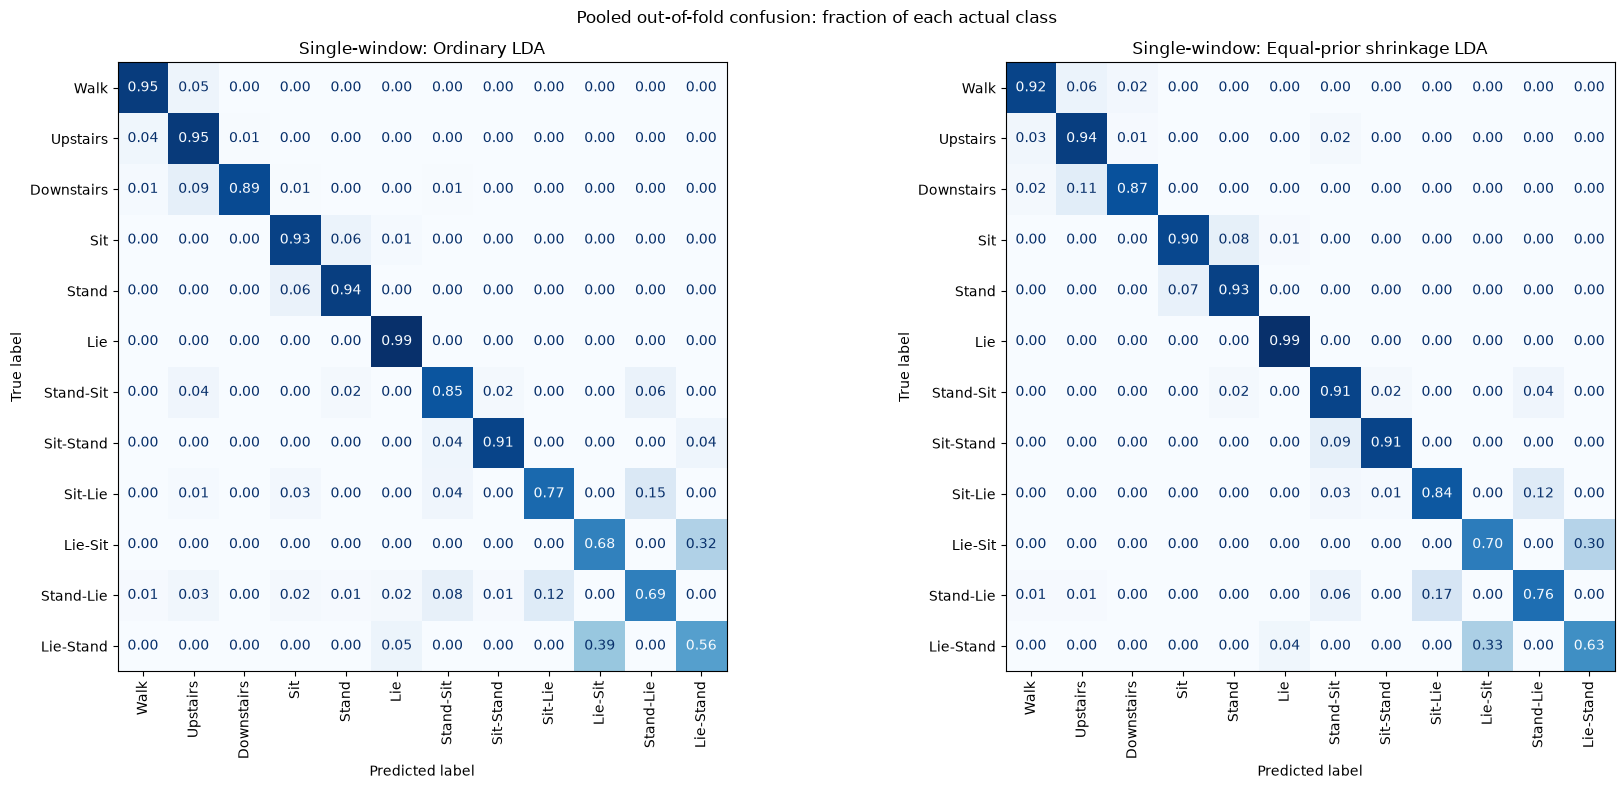

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix,
                             precision_recall_fscore_support)

activity_names = (train_df[['activity_id', 'activity_label']].drop_duplicates()
                  .set_index('activity_id')['activity_label'].reindex(all_labels))
short_names = ['Walk', 'Upstairs', 'Downstairs', 'Sit', 'Stand', 'Lie',
               'Stand-Sit', 'Sit-Stand', 'Sit-Lie', 'Lie-Sit',
               'Stand-Lie', 'Lie-Stand']


def collect_oof(predictions):
    oof = np.empty_like(y_train)
    for (_, va), predicted in zip(folds, predictions):
        oof[va] = predicted
    return oof


def transition_report(oof_predictions):
    rows = []
    for name, predicted in oof_predictions.items():
        precision, recall, f1, support = precision_recall_fscore_support(
            y_train, predicted, labels=transition_labels, zero_division=0)
        for i, label in enumerate(transition_labels):
            rows.append({'configuration': name, 'activity': activity_names[label],
                         'precision': precision[i], 'recall': recall[i],
                         'f1': f1[i], 'support': support[i]})
    return pd.DataFrame(rows)


def plot_confusions(predictions, titles):
    fig, axes = plt.subplots(1, len(predictions),
                             figsize=(9 * len(predictions), 8), squeeze=False)
    for ax, predicted, title in zip(axes.flat, predictions, titles):
        matrix = confusion_matrix(y_train, predicted, labels=all_labels,
                                  normalize='true')
        ConfusionMatrixDisplay(matrix, display_labels=short_names).plot(
            ax=ax, cmap='Blues', colorbar=False, values_format='.2f',
            xticks_rotation=90)
        ax.set_title(title)
    fig.suptitle('Pooled out-of-fold confusion: fraction of each actual class')
    fig.tight_layout()
    plt.show()


single_oof = {name: collect_oof(predictions)
              for name, predictions in validation_predictions.items()}
single_transition_report = transition_report(single_oof)
display(single_transition_report.round(4))
single_reference = comparison.index[0]
plot_confusions([single_oof['Ordinary LDA'], single_oof[single_reference]],
                ['Single-window: Ordinary LDA', f'Single-window: {single_reference}'])

## 10. Prepare three-window inputs

For each window, follow the team's context preparation approach and combine the previous row's 561 features, the current row's
561 features and the next row's 561 features into one input with **1,683
features**. The target is the current row's activity. Keep the original row
order and use neighbours only when they belong to the same participant. At
the first or last row, or where participants change, replace an unavailable
neighbour with the current row. Check that the prepared data matches the
original training-file order before building these inputs.

The [dataset documentation](../../smartphone+based+recognition+of+human+activities+and+postural+transitions/README.txt)
describes 2.56-second overlapping windows, but the prepared feature files have
no per-window timestamps or recording IDs. Matching original row order does
not establish temporal continuity: this experiment assumes within-participant
row adjacency, and may cross gaps or recording boundaries within one person.
No activity labels are used to choose neighbours or reset context.

This is an **offline, or delayed-prediction, representation** because it needs
the next window. It cannot produce an immediate prediction using only current
and past readings. Build context in preserved order before slicing folds;
participant-grouped splits keep all contributing feature rows on the same
side of each split. Only training-set features are used here.

In [11]:
original_data = ROOT / 'smartphone+based+recognition+of+human+activities+and+postural+transitions'
np.testing.assert_array_equal(
    subject_train, np.loadtxt(original_data / 'Train/subject_id_train.txt', dtype=int))
np.testing.assert_array_equal(
    y_train, np.loadtxt(original_data / 'Train/y_train.txt', dtype=int))
original_features = np.loadtxt(original_data / 'Train/X_train.txt')
np.testing.assert_allclose(X_train, original_features, rtol=0, atol=1e-12)
del original_features

row_index = np.arange(len(X_train))
previous_index = np.maximum(row_index - 1, 0)
next_index = np.minimum(row_index + 1, len(X_train) - 1)
previous_index[subject_train[previous_index] != subject_train] = row_index[
    subject_train[previous_index] != subject_train]
next_index[subject_train[next_index] != subject_train] = row_index[
    subject_train[next_index] != subject_train]
X_three = np.hstack([X_train[previous_index], X_train, X_train[next_index]])
assert X_three.shape == (len(X_train), 1683)
assert np.array_equal(subject_train[previous_index], subject_train)
assert np.array_equal(subject_train[next_index], subject_train)
print('Original training-file row order verified; context shape:', X_three.shape)
print('Current-row padding:', np.count_nonzero(previous_index == row_index),
      'previous neighbours;', np.count_nonzero(next_index == row_index), 'next neighbours.')

Original training-file row order verified; context shape: (7767, 1683)
Current-row padding: 21 previous neighbours; 21 next neighbours.


## 11. Train and validate three-window LDA

Reuse the exact fold indices and four LDA settings from the single-window
experiment. Fit a fresh scaler on each fold's three-window training features,
then transform its validation features. Each model keeps `solver='lsqr'`,
with no PCA, resampling or additional tuning. This adds 12 fits. Reuse the same
metric function and validation labels so the input representation is the
controlled change. Store predictions for error analysis; do not evaluate or
construct context from the official test set.

In [12]:
context_models = {name: [] for name in configurations}
context_predictions = {name: [] for name in configurations}
context_scalers = []
context_rows = []

for fold, (tr, va) in enumerate(folds, start=1):
    scaler = StandardScaler()
    fit_x = scaler.fit_transform(X_three[tr])
    validation_x = scaler.transform(X_three[va])
    context_scalers.append(scaler)
    for name, settings in configurations.items():
        model = LinearDiscriminantAnalysis(solver='lsqr', **settings)
        model.fit(fit_x, y_train[tr])
        predicted = model.predict(validation_x)
        context_models[name].append(model)
        context_predictions[name].append(predicted)
        context_rows.append({'configuration': name, 'fold': fold,
                             **validation_metrics(y_train[va], predicted)})
    print(f'Fold {fold}: four three-window models fitted and validated.')

context_results = pd.DataFrame(context_rows)
display(context_results.round(4))

Fold 1: four three-window models fitted and validated.


Fold 2: four three-window models fitted and validated.


Fold 3: four three-window models fitted and validated.


,configuration,fold,transition_macro_f1,overall_macro_f1,accuracy
0,Ordinary LDA,1,0.8713,0.9075,0.9435
1,Shrinkage LDA,1,0.8480,0.8979,0.9458
2,Equal-prior LDA,1,0.8495,0.8954,0.9400
3,Equal-prior shrinkage LDA,1,0.8565,0.8940,0.9323
4,Ordinary LDA,2,0.8334,0.8903,0.9424
5,Shrinkage LDA,2,0.8384,0.8894,0.9370
6,Equal-prior LDA,2,0.8353,0.8906,0.9408
7,Equal-prior shrinkage LDA,2,0.8993,0.9186,0.9377
8,Ordinary LDA,3,0.9152,0.9227,0.9330
9,Shrinkage LDA,3,0.9099,0.9245,0.9399


## 12. Compare inputs and inspect changed errors

Compare all eight input/configuration combinations using mean and sample
standard deviation across the same three folds. The paired table subtracts
single-window scores from three-window scores for each configuration and fold;
positive changes favour context. Count how many folds improve, rather than
relying on the average alone. These standard deviations are descriptive, not
confidence intervals or significance tests.

For the highest-ranked three-window configuration, compare its transition
precision, recall and F1 with the same configuration's single-window results.
Show both confusion matrices to compare which activities are confused.

transition_macro_f1          \
                                                       mean     std   
input         configuration                                           
Single window Equal-prior shrinkage LDA              0.7567  0.0456   
              Ordinary LDA                           0.7382  0.0315   
              Equal-prior LDA                        0.7295  0.0699   
              Shrinkage LDA                          0.7229  0.0491   
Three windows Equal-prior shrinkage LDA              0.8917  0.0321   
              Ordinary LDA                           0.8733  0.0409   
              Shrinkage LDA                          0.8654  0.0388   
              Equal-prior LDA                        0.8618  0.0344   

                                        overall_macro_f1         accuracy  \
                                                    mean     std     mean   
input         configuration                                                 
Single window Equal-prior shrinkage LDA           0.8415  0.0249   0.9206   
              Ordinary LDA                        0.8398  0.0134   0.9337   
              Equal-prior LDA                     0.8336  0.0343   0.9298   
              Shrinkage LDA                       0.8273  0.0225   0.9246   
Three windows Equal-prior shrinkage LDA           0.9139  0.0180   0.9367   
              Ordinary LDA                        0.9068  0.0162   0.9396   
              Shrinkage LDA                       0.9039  0.0184   0.9409   
              Equal-prior LDA                     0.9006  0.0134   0.9378   

                                                 
                                            std  
input         configuration                      
Single window Equal-prior shrinkage LDA  0.0049  
              Ordinary LDA               0.0023  
              Equal-prior LDA            0.0029  
              Shrinkage LDA              0.0019  
Three windows Equal-prior shrinkage LDA  0.0039  
              Ordinary LDA               0.0058  
              Shrinkage LDA              0.0045  
              Equal-prior LDA            0.0045

,transition_f1_change,change_std,folds_improved,overall_f1_change,accuracy_change
configuration,,,,,
Equal-prior LDA,0.1323,0.0552,3,0.0670,0.0080
Equal-prior shrinkage LDA,0.1350,0.0144,3,0.0723,0.0161
Ordinary LDA,0.1351,0.0380,3,0.0670,0.0059
Shrinkage LDA,0.1425,0.0548,3,0.0767,0.0164


Per-transition comparison for: Equal-prior shrinkage LDA


,activity,precision_single,recall_single,f1_single,support,precision_three,recall_three,f1_three,f1_change
0,STAND_TO_SIT,0.5443,0.9149,0.6825,47,0.9167,0.9362,0.9263,0.2438
1,SIT_TO_STAND,0.8750,0.9130,0.8936,23,0.9565,0.9565,0.9565,0.0629
2,SIT_TO_LIE,0.7412,0.8400,0.7875,75,0.8354,0.8800,0.8571,0.0696
3,LIE_TO_SIT,0.6885,0.7000,0.6942,60,0.8525,0.8667,0.8595,0.1653
4,STAND_TO_LIE,0.8608,0.7556,0.8047,90,0.8989,0.8889,0.8939,0.0891
5,LIE_TO_STAND,0.6545,0.6316,0.6429,57,0.8571,0.8421,0.8496,0.2067


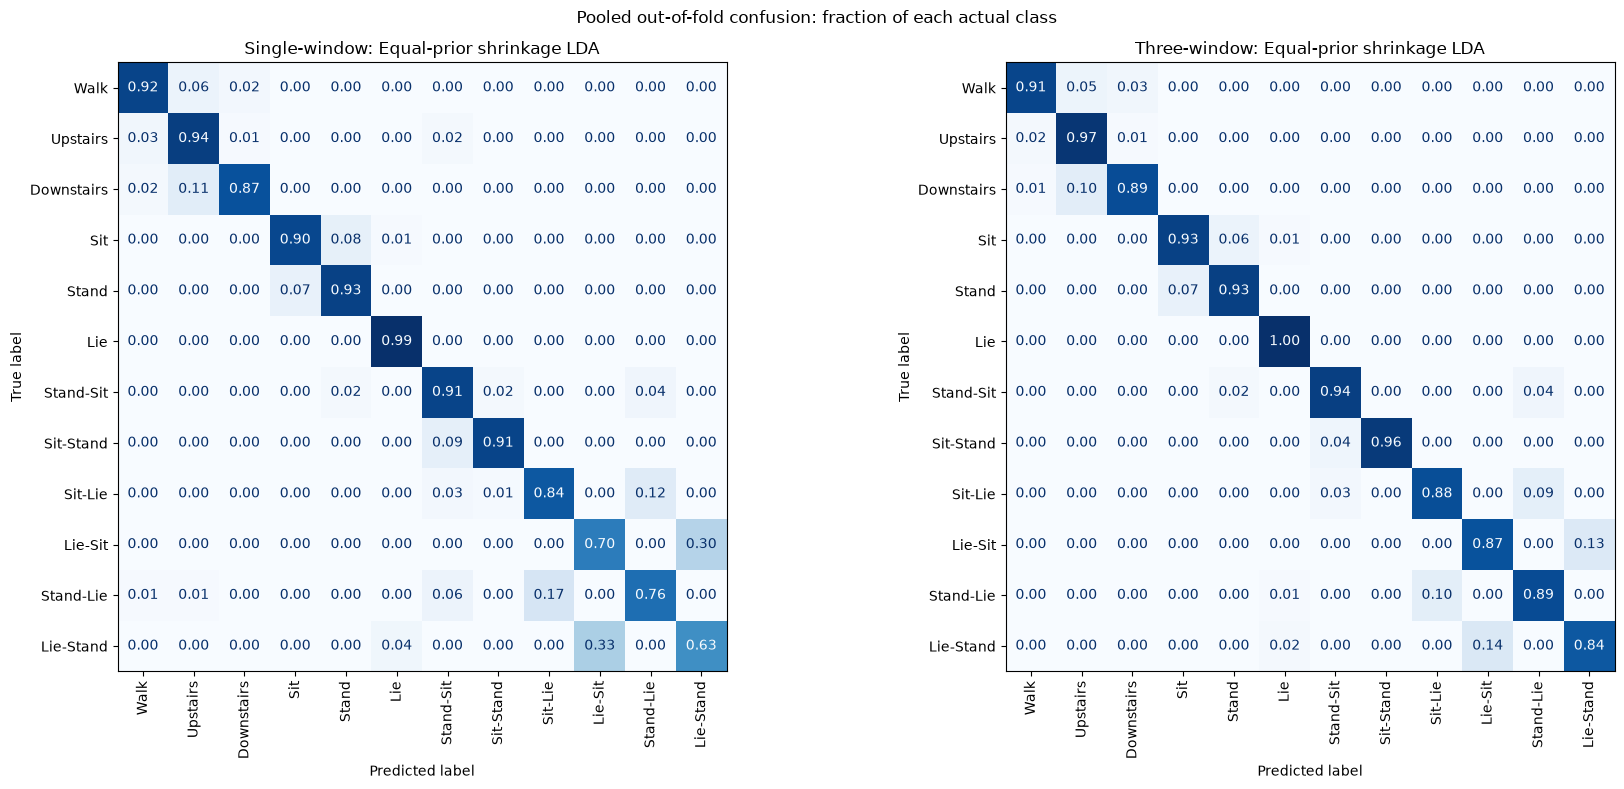

In [13]:
context_comparison = (context_results.groupby('configuration')[metric_columns]
                      .agg(['mean', 'std'])
                      .sort_values(('transition_macro_f1', 'mean'), ascending=False))
input_comparison = pd.concat({'Single window': comparison,
                              'Three windows': context_comparison}, names=['input'])
display(input_comparison.round(4))

paired_results = validation_results.merge(
    context_results, on=['configuration', 'fold'], suffixes=('_single', '_three'),
    validate='one_to_one')
for metric in metric_columns:
    paired_results[f'{metric}_change'] = (paired_results[f'{metric}_three']
                                         - paired_results[f'{metric}_single'])
context_effect = paired_results.groupby('configuration').agg(
    transition_f1_change=('transition_macro_f1_change', 'mean'),
    change_std=('transition_macro_f1_change', 'std'),
    folds_improved=('transition_macro_f1_change', lambda change: int((change > 0).sum())),
    overall_f1_change=('overall_macro_f1_change', 'mean'),
    accuracy_change=('accuracy_change', 'mean'))
display(context_effect.round(4))

context_oof = {name: collect_oof(predictions)
               for name, predictions in context_predictions.items()}
context_transition_report = transition_report(context_oof)
context_reference = context_comparison.index[0]
transition_change = (single_transition_report.query('configuration == @context_reference')
                     .drop(columns='configuration')
                     .merge(context_transition_report.query('configuration == @context_reference')
                            .drop(columns=['configuration', 'support']),
                            on='activity', suffixes=('_single', '_three'),
                            validate='one_to_one'))
transition_change['f1_change'] = transition_change['f1_three'] - transition_change['f1_single']
print('Per-transition comparison for:', context_reference)
display(transition_change.round(4))
plot_confusions([single_oof[context_reference], context_oof[context_reference]],
                [f'Single-window: {context_reference}',
                 f'Three-window: {context_reference}'])

**Individual transition errors**

The table shows the first two examples of each outcome when switching from
single-window to three-window input: **fixed** means wrong to correct,
**regressed** means correct to wrong, and **still wrong** means both are wrong.
Row IDs count data rows from 0, so ID 42 means the 43rd data row. These examples
show what changed, but do not establish why an error occurred.

In [14]:
single_pred = single_oof[context_reference]
context_pred = context_oof[context_reference]
example_rows = np.flatnonzero((y_train >= 7) &
                              ((single_pred != y_train) | (context_pred != y_train)))
examples = pd.DataFrame({
    'row': example_rows,
    'participant': subject_train[example_rows],
    'actual': activity_names.loc[y_train[example_rows]].to_numpy(),
    'single_prediction': activity_names.loc[single_pred[example_rows]].to_numpy(),
    'three_prediction': activity_names.loc[context_pred[example_rows]].to_numpy(),
    'outcome': np.where(context_pred[example_rows] == y_train[example_rows], 'fixed',
                       np.where(single_pred[example_rows] == y_train[example_rows],
                                'regressed', 'still wrong')),
})
# First two rows in each outcome category, preserving original file order.
display(examples.groupby('outcome', sort=False).head(2))

,row,participant,actual,single_prediction,three_prediction,outcome
0,42,1,STAND_TO_LIE,STAND_TO_LIE,SIT_TO_LIE,regressed
1,43,1,STAND_TO_LIE,SIT_TO_LIE,STAND_TO_LIE,fixed
2,56,1,LIE_TO_SIT,LIE_TO_STAND,LIE_TO_SIT,fixed
5,267,1,LIE_TO_STAND,LIE_TO_SIT,LIE_TO_SIT,still wrong
9,770,5,STAND_TO_LIE,SIT_TO_LIE,SIT_TO_LIE,still wrong
23,2246,11,SIT_TO_LIE,SIT_TO_LIE,STAND_TO_LIE,regressed


Context improves transition macro-F1 for all four configurations on all three
original folds. For equal-prior shrinkage LDA, the largest pooled class-F1 gains
are stand-to-sit and lie-to-stand. The individual examples still include
regressions, so surrounding windows do not help every prediction.

## 13. Tune shrinkage strength

Use three-window inputs because they improved every configuration in Section 12.
Test fixed shrinkage strengths **0.0001, 0.001, 0.01, 0.1, 0.5 and 1.0**, each
with empirical or equal priors. Larger fixed values apply stronger covariance
regularisation; `auto` estimates shrinkage rather than searching for the best
transition F1. Keep `lsqr`, the original folds and training-only scaling. Rank
by mean transition F1, then overall macro-F1 and accuracy to break exact ties.

[Parameter definitions](https://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.LinearDiscriminantAnalysis.html)

In [16]:
fixed_strengths = [0.0001, 0.001, 0.01, 0.1, 0.5, 1.0]
prior_options = {'empirical': None, 'equal': np.full(12, 1 / 12)}
fixed_candidates = {
    f'Fixed {strength:g} ({prior_name})': {'shrinkage': strength, 'priors': priors}
    for strength in fixed_strengths for prior_name, priors in prior_options.items()
}
tuning_predictions = {name: [] for name in fixed_candidates}
tuning_rows = []

for fold, (tr, va) in enumerate(folds, start=1):
    # These scalers were fitted on the same three-window training folds in Section 11.
    scaler = context_scalers[fold - 1]
    fit_x = scaler.transform(X_three[tr])
    validation_x = scaler.transform(X_three[va])
    for name, settings in fixed_candidates.items():
        model = LinearDiscriminantAnalysis(solver='lsqr', **settings)
        model.fit(fit_x, y_train[tr])
        predicted = model.predict(validation_x)
        tuning_predictions[name].append(predicted)
        tuning_rows.append({'configuration': name, 'fold': fold,
                            **validation_metrics(y_train[va], predicted)})
    print(f'Fold {fold}: completed the 12 fixed-shrinkage candidates.')

fixed_results = pd.DataFrame(tuning_rows)
search_results = pd.concat([context_results, fixed_results], ignore_index=True)
search_results.insert(0, 'split_seed', 42)
ranking_columns = [(metric, 'mean') for metric in metric_columns]
search_summary = (search_results.groupby('configuration')[metric_columns]
                  .agg(['mean', 'std'])
                  .sort_values(ranking_columns, ascending=False))
display(search_summary.round(4))

Fold 1: completed the 12 fixed-shrinkage candidates.


Fold 2: completed the 12 fixed-shrinkage candidates.


Fold 3: completed the 12 fixed-shrinkage candidates.


transition_macro_f1         overall_macro_f1  \
                                         mean     std             mean   
configuration                                                            
Equal-prior shrinkage LDA              0.8917  0.0321           0.9139   
Fixed 0.01 (equal)                     0.8748  0.0381           0.9086   
Fixed 0.1 (equal)                      0.8739  0.0354           0.9057   
Ordinary LDA                           0.8733  0.0409           0.9068   
Fixed 0.5 (empirical)                  0.8719  0.0403           0.9009   
Fixed 0.1 (empirical)                  0.8704  0.0402           0.9045   
Fixed 0.5 (equal)                      0.8695  0.0117           0.8965   
Fixed 0.0001 (equal)                   0.8685  0.0368           0.9053   
Fixed 0.001 (equal)                    0.8671  0.0356           0.9057   
Fixed 0.001 (empirical)                0.8667  0.0478           0.9054   
Shrinkage LDA                          0.8654  0.0388           0.9039   
Fixed 0.01 (empirical)                 0.8647  0.0434           0.9047   
Equal-prior LDA                        0.8618  0.0344           0.9006   
Fixed 0.0001 (empirical)               0.8606  0.0349           0.9016   
Fixed 1 (empirical)                    0.6974  0.0609           0.7306   
Fixed 1 (equal)                        0.6950  0.0592           0.7295   

                                  accuracy          
                              std     mean     std  
configuration                                       
Equal-prior shrinkage LDA  0.0180   0.9367  0.0039  
Fixed 0.01 (equal)         0.0180   0.9414  0.0023  
Fixed 0.1 (equal)          0.0213   0.9368  0.0069  
Ordinary LDA               0.0162   0.9396  0.0058  
Fixed 0.5 (empirical)      0.0260   0.9293  0.0114  
Fixed 0.1 (empirical)      0.0213   0.9379  0.0036  
Fixed 0.5 (equal)          0.0129   0.9231  0.0130  
Fixed 0.0001 (equal)       0.0150   0.9408  0.0042  
Fixed 0.001 (equal)        0.0144   0.9425  0.0045  
Fixed 0.001 (empirical)    0.0204   0.9427  0.0046  
Shrinkage LDA              0.0184   0.9409  0.0045  
Fixed 0.01 (empirical)     0.0198   0.9431  0.0047  
Equal-prior LDA            0.0134   0.9378  0.0045  
Fixed 0.0001 (empirical)   0.0135   0.9412  0.0051  
Fixed 1 (empirical)        0.0551   0.7641  0.0538  
Fixed 1 (equal)            0.0547   0.7641  0.0537

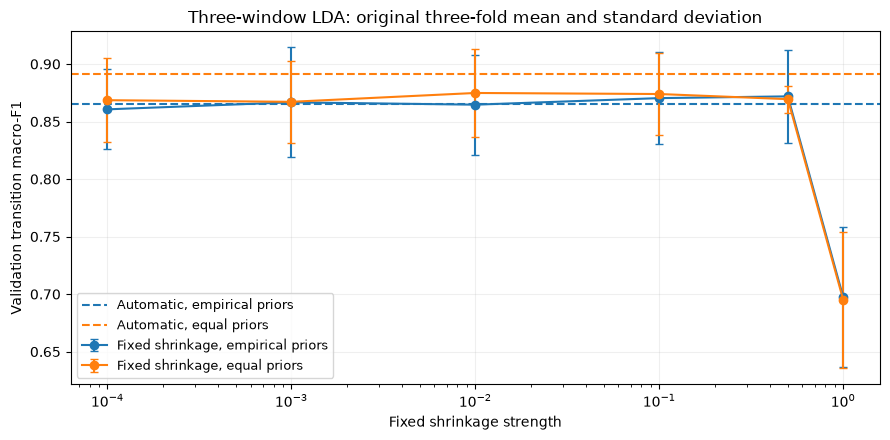

In [17]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for prior_name, colour, automatic_name in [
    ('empirical', 'tab:blue', 'Shrinkage LDA'),
    ('equal', 'tab:orange', 'Equal-prior shrinkage LDA'),
]:
    names = [f'Fixed {strength:g} ({prior_name})' for strength in fixed_strengths]
    means = search_summary.loc[names, ('transition_macro_f1', 'mean')].to_numpy()
    deviations = search_summary.loc[names, ('transition_macro_f1', 'std')].to_numpy()
    ax.errorbar(fixed_strengths, means, yerr=deviations, marker='o',
                capsize=3, color=colour, label=f'Fixed shrinkage, {prior_name} priors')
    ax.axhline(search_summary.loc[automatic_name, ('transition_macro_f1', 'mean')],
               color=colour, linestyle='--', label=f'Automatic, {prior_name} priors')
ax.set(xscale='log', xlabel='Fixed shrinkage strength',
       ylabel='Validation transition macro-F1',
       title='Three-window LDA: original three-fold mean and standard deviation')
ax.legend(fontsize=9)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## 14. Check consistency across participant splits

Check the same four configurations on different participant arrangements,
without adding candidates or changing their settings. Refit scaling and models
inside each training fold. Changing the stratified seed repeated the original
folds, so use shuffled `GroupKFold` with seeds **123 and 2026** for the additional
arrangements. Check distinct partitions, participant separation and class
coverage. These validation checks reuse the same 21 training participants;
they are not independent test results.

[Grouped-split documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupKFold.html)

In [2]:
from sklearn.model_selection import GroupKFold

shortlisted_fixed = search_summary.loc[
    search_summary.index.isin(fixed_candidates)].head(2).index.tolist()
automatic_reference = next(name for name in context_comparison.index
                           if configurations[name]['shrinkage'] == 'auto')
consistency_candidates = {
    'Ordinary LDA': configurations['Ordinary LDA'],
    automatic_reference: configurations[automatic_reference],
    **{name: fixed_candidates[name] for name in shortlisted_fixed},
}
consistency_splits = {42: folds}
partition_signatures = {
    tuple(sorted(tuple(np.unique(subject_train[va])) for _, va in folds))
}
consistency_predictions = {
    (42, name): (tuning_predictions[name] if name in fixed_candidates
                 else context_predictions[name])
    for name in consistency_candidates
}
consistency_rows = search_results.loc[
    search_results.configuration.isin(consistency_candidates)].to_dict('records')

for seed in [123, 2026]:
    splitter = GroupKFold(n_splits=3, shuffle=True, random_state=seed)
    split_folds = list(splitter.split(X_three, y_train, groups=subject_train))
    signature = tuple(sorted(tuple(np.unique(subject_train[va])) for _, va in split_folds))
    assert signature not in partition_signatures
    partition_signatures.add(signature)
    consistency_splits[seed] = split_folds
    for name in consistency_candidates:
        consistency_predictions[(seed, name)] = []
    for fold, (tr, va) in enumerate(split_folds, start=1):
        assert set(subject_train[tr]).isdisjoint(subject_train[va])
        assert set(y_train[tr]) == set(y_train[va]) == set(all_labels)
        scaler = StandardScaler()
        fit_x = scaler.fit_transform(X_three[tr])
        validation_x = scaler.transform(X_three[va])
        for name, settings in consistency_candidates.items():
            model = LinearDiscriminantAnalysis(solver='lsqr', **settings)
            model.fit(fit_x, y_train[tr])
            predicted = model.predict(validation_x)
            consistency_predictions[(seed, name)].append(predicted)
            consistency_rows.append({
                'split_seed': seed, 'configuration': name, 'fold': fold,
                **validation_metrics(y_train[va], predicted),
            })
    print(f'Seed {seed}: completed three participant-grouped folds.')

consistency_results = pd.DataFrame(consistency_rows)
consistency_summary = (consistency_results.groupby('configuration')[metric_columns]
                       .agg(['mean', 'std'])
                       .sort_values(ranking_columns, ascending=False))
seed_means = (consistency_results.groupby(['configuration', 'split_seed'])
              ['transition_macro_f1'].mean().unstack('split_seed'))
from IPython.display import Markdown

partition_labels = {42: 'Original stratified (seed 42)',
                    123: 'Shuffled groups (seed 123)',
                    2026: 'Shuffled groups (seed 2026)'}
display(Markdown('**Mean validation transition macro-F1: three folds per participant arrangement**'),
        seed_means.rename(columns=partition_labels).rename_axis(
            index='Configuration', columns='Participant arrangement').round(4))
display(Markdown('**Validation across all nine folds: mean and sample standard deviation**'),
        consistency_summary.rename(columns={
            'transition_macro_f1': 'Transition macro-F1',
            'overall_macro_f1': 'Overall macro-F1', 'accuracy': 'Accuracy',
            'mean': 'Mean', 'std': 'Std. deviation'}).rename_axis('Configuration').round(4))

Seed 123: completed three participant-grouped folds.
Seed 2026: completed three participant-grouped folds.


**Mean validation transition macro-F1: three folds per participant arrangement**

Participant arrangement,Original stratified (seed 42),Shuffled groups (seed 123),Shuffled groups (seed 2026)
Configuration,,,
Equal-prior shrinkage LDA,0.8917,0.8966,0.8724
Fixed 0.01 (equal),0.8748,0.8801,0.8662
Fixed 0.1 (equal),0.8739,0.8918,0.8730
Ordinary LDA,0.8733,0.8643,0.8702


**Validation across all nine folds: mean and sample standard deviation**

Transition macro-F1  ...               
                                         Mean  ... Std. deviation
Configuration                                  ...               
Equal-prior shrinkage LDA              0.8869  ...         0.0201
Fixed 0.1 (equal)                      0.8796  ...         0.0202
Fixed 0.01 (equal)                     0.8737  ...         0.0172
Ordinary LDA                           0.8693  ...         0.0125

[4 rows x 6 columns]

## 15. Add posture memory

Sit-to-lie and stand-to-lie share the same ending posture, so earlier predicted
posture may help distinguish their starting positions. Adapt the
[team's posture-memory rule](<../24_10_2026_TianFeng/nn_model.ipynb>) to
automatic-shrinkage, equal-prior LDA, the strongest validation reference.
Sum predicted sitting and standing probabilities from up to **eight previous
windows** of the same participant. If their combined mass reaches **0.75**,
choose stand-to-lie when standing evidence is greater; otherwise choose
sit-to-lie. With insufficient evidence, keep the original prediction.

Only these two transition predictions can change. The threshold applies to a
sum of model probabilities, not 75% confidence. Keep the rule fixed, use no
true activity labels, and reset history between participants. This is
postprocessing; it does not retrain LDA or feed adjusted labels back into history.

In [18]:
memory_base_name = automatic_reference
memory_lda_settings = consistency_candidates[memory_base_name].copy()
memory_name = memory_base_name + ' + posture memory'
memory_steps = 8
memory_minimum_static_mass = 0.75


def lda_posture_memory(probabilities, classes, people, steps=8, minimum_static_mass=0.75):
    columns = {int(label): i for i, label in enumerate(classes)}
    predicted = np.asarray(classes)[probabilities.argmax(axis=1)].copy()
    start = 0
    for row in range(len(people)):
        if row == 0 or people[row] != people[row - 1]:
            start = row
        # HAPT labels: sitting=4, standing=5, sit-to-lie=9, stand-to-lie=11.
        if predicted[row] not in (9, 11):
            continue
        past = probabilities[max(start, row - steps):row]
        evidence = past[:, [columns[4], columns[5]]].sum(axis=0)
        if evidence.sum() >= minimum_static_mass:
            predicted[row] = 11 if evidence[1] > evidence[0] else 9
    return predicted

## 16. Validate LDA with and without memory

Compare the same LDA with and without the fixed memory rule across the nine
folds from Section 14. Fit scaling and LDA on each fold's training participants
only. Process validation windows in original file order and keep each person's
history separate. Both versions use exactly the same fitted model and inputs;
memory is the only change. Report all three metrics and count how many folds
improve on transition macro-F1. These repeated splits reuse participants, so
their variation is descriptive rather than independent confirmation.

In [19]:
memory_validation_rows = []
memory_validation_predictions = {}
for seed, seed_folds in consistency_splits.items():
    for fold, (tr, va) in enumerate(seed_folds, start=1):
        assert np.all(np.diff(va) > 0)  # Preserve original order for posture history.
        assert set(subject_train[tr]).isdisjoint(subject_train[va])
        scaler = StandardScaler()
        fit_x = scaler.fit_transform(X_three[tr])
        validation_x = scaler.transform(X_three[va])
        model = LinearDiscriminantAnalysis(solver='lsqr', **memory_lda_settings)
        model.fit(fit_x, y_train[tr])
        probabilities = model.predict_proba(validation_x)
        plain = model.predict(validation_x)
        np.testing.assert_array_equal(plain, model.classes_[probabilities.argmax(axis=1)])
        np.testing.assert_array_equal(
            plain, consistency_predictions[(seed, memory_base_name)][fold - 1])
        adjusted = lda_posture_memory(
            probabilities, model.classes_, subject_train[va],
            steps=memory_steps, minimum_static_mass=memory_minimum_static_mass)
        memory_validation_predictions[(seed, fold)] = {
            'LDA': plain, 'LDA + posture memory': adjusted}
        for method, predicted in memory_validation_predictions[(seed, fold)].items():
            memory_validation_rows.append({
                'Method': method, 'split_seed': seed, 'fold': fold,
                **validation_metrics(y_train[va], predicted),
            })
    print(f'Seed {seed}: compared LDA with and without memory on three folds.')

memory_validation_results = pd.DataFrame(memory_validation_rows)
memory_validation_summary = (
    memory_validation_results.groupby('Method')[metric_columns].agg(['mean', 'std']))
metric_names = {'transition_macro_f1': 'Transition macro-F1',
                'overall_macro_f1': 'Overall macro-F1', 'accuracy': 'Accuracy'}
display(Markdown('**Validation across nine folds: mean and sample standard deviation**'),
        memory_validation_summary.rename(columns={
            **metric_names, 'mean': 'Mean', 'std': 'Std. deviation'}).round(4))

memory_seed_means = (
    memory_validation_results.groupby(['Method', 'split_seed'])
    ['transition_macro_f1'].mean().unstack('split_seed'))
display(Markdown('**Mean validation transition macro-F1: three folds per arrangement**'),
        memory_seed_means.rename(columns=partition_labels).rename_axis(
            columns='Participant arrangement').round(4))

memory_paired = memory_validation_results.pivot(
    index=['split_seed', 'fold'], columns='Method', values='transition_macro_f1')
memory_changes = memory_paired['LDA + posture memory'] - memory_paired['LDA']
print(f'Transition macro-F1 improved in {(memory_changes > 0).sum()}/9 folds; '
      f'mean change: {memory_changes.mean():+.4f}.')

Seed 42: compared LDA with and without memory on three folds.


Seed 123: compared LDA with and without memory on three folds.


Seed 2026: compared LDA with and without memory on three folds.


**Validation across nine folds: mean and sample standard deviation**

Transition macro-F1                Overall macro-F1  \
                                    Mean Std. deviation             Mean   
Method                                                                     
LDA                               0.8869         0.0352           0.9127   
LDA + posture memory              0.9134         0.0340           0.9259   

                                    Accuracy                 
                     Std. deviation     Mean Std. deviation  
Method                                                       
LDA                          0.0257   0.9374         0.0201  
LDA + posture memory         0.0248   0.9392         0.0197

**Mean validation transition macro-F1: three folds per arrangement**

Participant arrangement,Original stratified (seed 42),Shuffled groups (seed 123),Shuffled groups (seed 2026)
Method,,,
LDA,0.8917,0.8966,0.8724
LDA + posture memory,0.9197,0.9185,0.9020


Transition macro-F1 improved in 9/9 folds; mean change: +0.0265.


## 17. Compare the fixed candidates on the test set

Compare the four configurations from Section 14 and automatic-shrinkage,
equal-prior LDA with posture memory. Fit scaling and each LDA on all 21
training participants. Build test context separately with the same boundary
padding, then apply the training-fitted scaler. The memory version reuses the
same fitted LDA and its predicted probabilities, resetting history between
test participants. Report all five results on the 3,162 test windows without
changing model settings or the memory rule in response to these scores.

In [20]:
# Keep the validation shortlist and memory settings fixed for this comparison.
test_candidates = {name: settings.copy()
                   for name, settings in consistency_candidates.items()}
# Verify original test-row order before using neighbouring rows.
np.testing.assert_array_equal(
    subject_test, np.loadtxt(original_data / 'Test/subject_id_test.txt', dtype=int))
np.testing.assert_array_equal(
    y_test, np.loadtxt(original_data / 'Test/y_test.txt', dtype=int))
np.testing.assert_allclose(
    X_test, np.loadtxt(original_data / 'Test/X_test.txt'), rtol=0, atol=1e-12)
test_index = np.arange(len(X_test))
test_previous_index = np.maximum(test_index - 1, 0)
test_next_index = np.minimum(test_index + 1, len(X_test) - 1)
previous_boundary = subject_test[test_previous_index] != subject_test
next_boundary = subject_test[test_next_index] != subject_test
test_previous_index[previous_boundary] = test_index[previous_boundary]
test_next_index[next_boundary] = test_index[next_boundary]
X_test_three = np.hstack([X_test[test_previous_index], X_test,
                          X_test[test_next_index]])
assert X_test_three.shape == (3162, 1683)
assert np.array_equal(subject_test[test_previous_index], subject_test)
assert np.array_equal(subject_test[test_next_index], subject_test)

final_scaler = StandardScaler()
final_train_x = final_scaler.fit_transform(X_three)
final_test_x = final_scaler.transform(X_test_three)
test_models, test_predictions, test_rows = {}, {}, []
for name, settings in test_candidates.items():
    model = LinearDiscriminantAnalysis(solver='lsqr', **settings)
    model.fit(final_train_x, y_train)
    predicted = model.predict(final_test_x)
    test_models[name] = model
    test_predictions[name] = predicted
    test_rows.append({'configuration': name, **validation_metrics(y_test, predicted)})

memory_test_probabilities = test_models[memory_base_name].predict_proba(final_test_x)
memory_test_predictions = lda_posture_memory(
    memory_test_probabilities, test_models[memory_base_name].classes_, subject_test,
    steps=memory_steps, minimum_static_mass=memory_minimum_static_mass)
test_predictions[memory_name] = memory_test_predictions
test_rows.append({'configuration': memory_name,
                  **validation_metrics(y_test, memory_test_predictions)})

test_results = (pd.DataFrame(test_rows).set_index('configuration')
                .sort_values(metric_columns, ascending=False, kind='stable'))
display(Markdown('**Official test scores: 3,162 windows from nine participants**'),
        test_results.rename(columns={
            'transition_macro_f1': 'Transition macro-F1',
            'overall_macro_f1': 'Overall macro-F1',
            'accuracy': 'Accuracy'}).rename_axis('Configuration').round(4))

**Official test scores: 3,162 windows from nine participants**

,Transition macro-F1,Overall macro-F1,Accuracy
Configuration,,,
Equal-prior shrinkage LDA + posture memory,0.9500,0.9591,0.9674
Equal-prior shrinkage LDA,0.8992,0.9337,0.9636
Fixed 0.01 (equal),0.8927,0.9341,0.9696
Fixed 0.1 (equal),0.8720,0.9199,0.9617
Ordinary LDA,0.8708,0.9214,0.9649


## 18. Select the representative and examine errors

Retain the pipeline with the highest test transition macro-F1, using overall
macro-F1 and accuracy to break exact ties before rounding. Consider its
validation consistency alongside the test comparison, and keep plain LDA as
the baseline. Show transition metrics, both confusion matrices and examples
of predictions changed by memory. This is **development-test selection**:
test results help choose the representative, so its winning score is not an
independent final estimate.

LDA representative: Equal-prior shrinkage LDA + posture memory
Input: previous/current/next windows (1,683 features); solver: lsqr
Shrinkage: auto | Priors: equal
Posture memory: 8 previous windows; minimum accumulated sitting/standing mass: 0.75


**Representative: test metrics for the six transition activities**

,Precision,Recall,F1,Test windows
Activity,,,,
STAND_TO_SIT,0.8800,0.9565,0.9167,23
SIT_TO_STAND,1.0000,1.0000,1.0000,10
SIT_TO_LIE,1.0000,1.0000,1.0000,32
LIE_TO_SIT,0.8621,1.0000,0.9259,25
STAND_TO_LIE,0.9592,0.9592,0.9592,49
LIE_TO_STAND,1.0000,0.8148,0.8980,27


**Effect of posture memory on each transition**

,LDA F1,LDA + memory F1,F1 change,Test windows
Activity,,,,
STAND_TO_SIT,0.9167,0.9167,0.0000,23
SIT_TO_STAND,1.0000,1.0000,0.0000,10
SIT_TO_LIE,0.8286,1.0000,0.1714,32
LIE_TO_SIT,0.9259,0.9259,0.0000,25
STAND_TO_LIE,0.8261,0.9592,0.1331,49
LIE_TO_STAND,0.8980,0.8980,0.0000,27


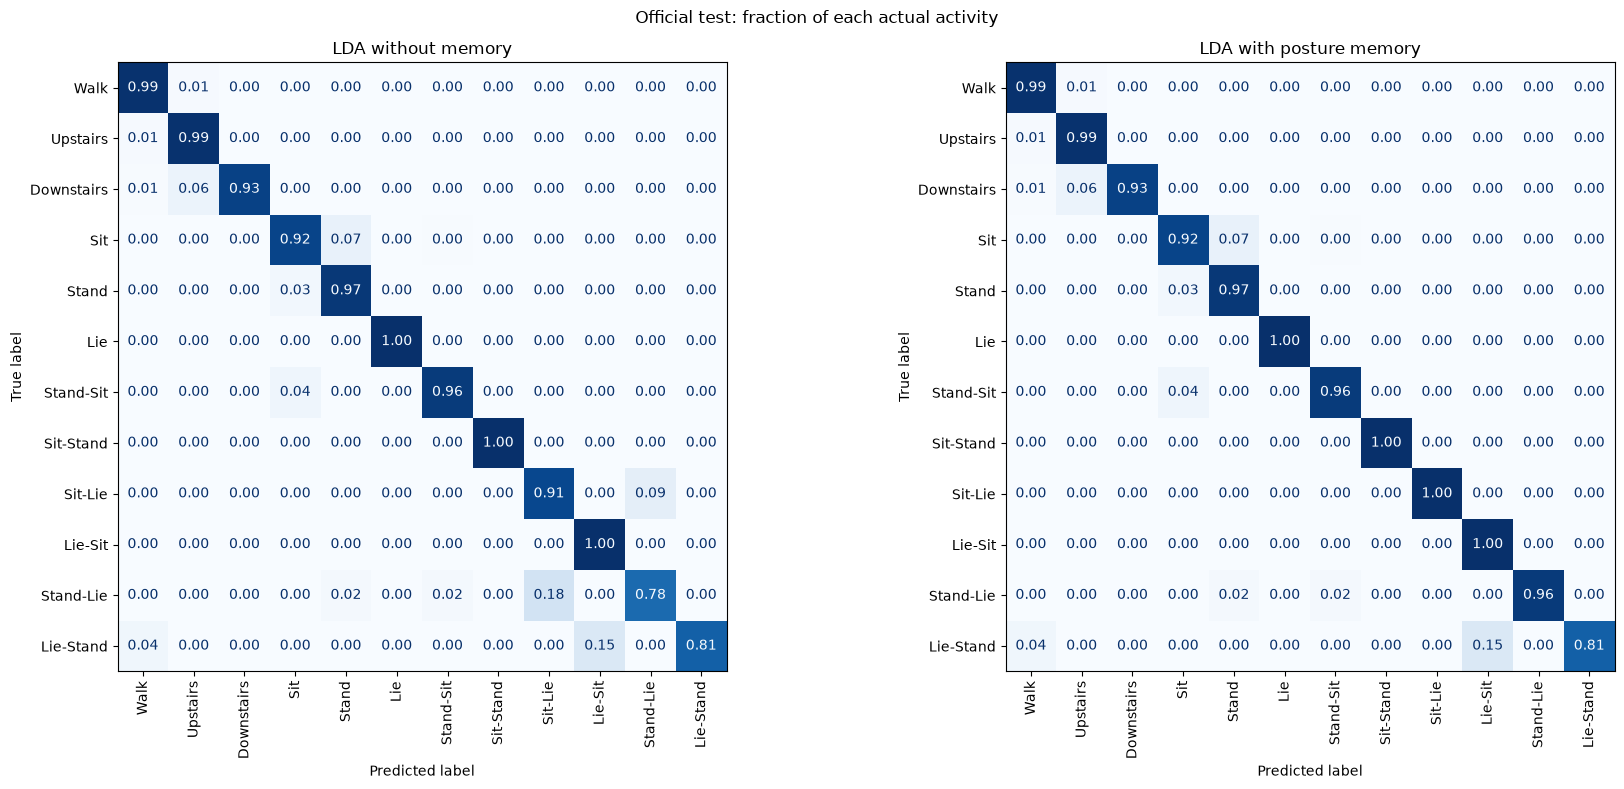

In [21]:
selected_lda_name = test_results.index[0]
selected_uses_memory = selected_lda_name == memory_name
selected_base_name = memory_base_name if selected_uses_memory else selected_lda_name
selected_lda = test_models[selected_base_name]
selected_lda_settings = test_candidates[selected_base_name].copy()
selected_test_predictions = test_predictions[selected_lda_name]
print('LDA representative:', selected_lda_name)
print('Input: previous/current/next windows (1,683 features); solver: lsqr')
print('Shrinkage:', selected_lda_settings['shrinkage'],
      '| Priors:', 'empirical' if selected_lda_settings['priors'] is None else 'equal')
if selected_uses_memory:
    print(f'Posture memory: {memory_steps} previous windows; '
          f'minimum accumulated sitting/standing mass: {memory_minimum_static_mass}')

precision, recall, f1, support = precision_recall_fscore_support(
    y_test, selected_test_predictions, labels=transition_labels, zero_division=0)
selected_transition_results = pd.DataFrame({
    'Activity': activity_names.loc[transition_labels].to_numpy(),
    'Precision': precision, 'Recall': recall, 'F1': f1, 'Test windows': support,
}).set_index('Activity')
display(Markdown('**Representative: test metrics for the six transition activities**'),
        selected_transition_results.round(4))

plain_test_predictions = test_predictions[memory_base_name]
plain_transition_f1 = precision_recall_fscore_support(
    y_test, plain_test_predictions, labels=transition_labels, zero_division=0)[2]
memory_transition_f1 = precision_recall_fscore_support(
    y_test, memory_test_predictions, labels=transition_labels, zero_division=0)[2]
memory_transition_comparison = pd.DataFrame({
    'Activity': activity_names.loc[transition_labels].to_numpy(),
    'LDA F1': plain_transition_f1, 'LDA + memory F1': memory_transition_f1,
    'F1 change': memory_transition_f1 - plain_transition_f1, 'Test windows': support,
}).set_index('Activity')
display(Markdown('**Effect of posture memory on each transition**'),
        memory_transition_comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, predicted, title in zip(
        axes, [plain_test_predictions, memory_test_predictions],
        ['LDA without memory', 'LDA with posture memory']):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicted, labels=all_labels, display_labels=short_names,
        normalize='true', values_format='.2f', cmap='Blues', colorbar=False,
        xticks_rotation=90, ax=ax)
    ax.set_title(title)
fig.suptitle('Official test: fraction of each actual activity')
fig.tight_layout()
plt.show()

**Predictions changed by memory**

Count corrections, regressions and changes that remain wrong, then show the
first three examples of each outcome in original file order. Row IDs start
at 0. Only sit-to-lie and stand-to-lie predictions can change; the table shows
what happened, rather than proving the physical cause of an error.

In [22]:
memory_changed = memory_test_predictions != plain_test_predictions
memory_corrected = memory_changed & (memory_test_predictions == y_test)
memory_worsened = memory_changed & (plain_test_predictions == y_test)
memory_still_wrong = memory_changed & ~memory_corrected & ~memory_worsened
print(f'Changed {memory_changed.sum()} test predictions: '
      f'{memory_corrected.sum()} corrected, {memory_worsened.sum()} worsened, '
      f'{memory_still_wrong.sum()} changed but still wrong.')

changed_rows = np.flatnonzero(memory_changed)
memory_examples = pd.DataFrame({
    'Row': changed_rows, 'Participant': subject_test[changed_rows],
    'Actual': activity_names.loc[y_test[changed_rows]].to_numpy(),
    'LDA prediction': activity_names.loc[plain_test_predictions[changed_rows]].to_numpy(),
    'With memory': activity_names.loc[memory_test_predictions[changed_rows]].to_numpy(),
    'Outcome': np.where(memory_corrected[changed_rows], 'fixed',
                        np.where(memory_worsened[changed_rows], 'regressed', 'still wrong')),
})
display(memory_examples.groupby('Outcome', sort=False).head(3))

Changed 12 test predictions: 12 corrected, 0 worsened, 0 changed but still wrong.


,Row,Participant,Actual,LDA prediction,With memory,Outcome
0,50,2,STAND_TO_LIE,SIT_TO_LIE,STAND_TO_LIE,fixed
1,51,2,STAND_TO_LIE,SIT_TO_LIE,STAND_TO_LIE,fixed
2,371,4,STAND_TO_LIE,SIT_TO_LIE,STAND_TO_LIE,fixed


## 19. Interpretation and limitations

We chose to retain three-window, equal-prior automatic-shrinkage LDA with
posture memory because it improved transition macro-F1 in all nine validation
folds and achieved the highest transition F1 in our test comparison. Mean
validation transition F1 rises from **0.8869 to 0.9134**. Test transition
macro-F1 is **0.9500**, overall macro-F1 **0.9591**, and accuracy **0.9674**.
Memory corrects 12 sit-to-lie/stand-to-lie confusions without introducing new
test errors. Lie-to-stand remains the weakest transition (F1 0.8980).
Plain LDA provides the baseline; fixed shrinkage 0.01 has higher accuracy
(0.9696), showing the trade-off when prioritising rare transitions.

The limitations include:

- **Delayed prediction:** the three-window input needs the next window, so the
  full pipeline cannot make an immediate prediction from current and past data.
- **Uncertain sequence boundaries:** the prepared feature files lack per-window
  timestamps and recording IDs. Neighbouring rows and memory may span gaps or
  separate recordings within one participant.
- **Incorrect posture evidence:** memory relies on predicted probabilities.
  Wrong earlier posture estimates can lead to incorrect transition decisions.
- **Scripted activity sequences:** the rule may benefit from the experiment's
  activity order and perform differently during everyday, unscripted activity.
- **Limited independent evidence:** rare transitions have few examples,
  overlapping windows are related, and the nine validation folds reuse the
  same 21 participants. Consistency across folds is not independent confirmation.
- **Development-test results:** the official test set was also used for representative selection. A frozen pipeline needs evaluation
  on new participants with verified sequence boundaries for an independent estimate.